# J-lens / R / J++ — corrected reproduction (Qwen3.5-9B, NF4, RTX 3070 Ti)

Numbers transcribed from `results/CORRECTED_REPRODUCTION.md`. **Descriptive evaluation, not a certified held-out replication of the paper tables.** Recall@10, item-weighted min-over-layers.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
lenses = ["Logit","J","R","J+readout only","J++"]
tasks = ["multihop","multilingual","typo","association","poetry","macro"]
data = {
 "all layers": [[47.62,60.12,54.56,62.30,73.02],[37.77,48.29,50.70,55.30,72.82],[58.33,59.38,76.04,69.79,97.92],[0.00,3.92,3.92,9.80,32.35],[1.02,3.06,2.04,3.06,11.22],[28.95,34.95,37.45,40.05,57.47]],
 "7 layers": [[38.69,47.02,45.24,52.98,61.71],[30.45,42.68,46.73,50.86,65.03],[43.75,45.83,60.42,53.12,93.75],[0.00,2.94,3.92,7.84,28.43],[0.00,2.04,1.02,3.06,7.14],[22.58,28.10,31.47,33.57,51.21]],
 "7 layers, correctness-filtered": [[73.44,70.31,75.00,71.88,79.69],[31.02,43.98,46.18,51.97,67.13],[43.75,45.83,60.42,53.12,93.75],[0.00,2.94,3.92,7.84,28.43],[0.00,2.70,1.35,4.05,9.46],[29.64,33.15,37.37,37.77,55.69]],
}
tables = {k: pd.DataFrame(v, index=tasks, columns=lenses) for k,v in data.items()}
for k,t in tables.items():
    print(f"\n== Recall@10 (%) — {k} =="); display(t)


== Recall@10 (%) — all layers ==


,Logit,J,R,J+readout only,J++
multihop,47.62,60.12,54.56,62.30,73.02
multilingual,37.77,48.29,50.70,55.30,72.82
typo,58.33,59.38,76.04,69.79,97.92
association,0.00,3.92,3.92,9.80,32.35
poetry,1.02,3.06,2.04,3.06,11.22
macro,28.95,34.95,37.45,40.05,57.47



== Recall@10 (%) — 7 layers ==


,Logit,J,R,J+readout only,J++
multihop,38.69,47.02,45.24,52.98,61.71
multilingual,30.45,42.68,46.73,50.86,65.03
typo,43.75,45.83,60.42,53.12,93.75
association,0.00,2.94,3.92,7.84,28.43
poetry,0.00,2.04,1.02,3.06,7.14
macro,22.58,28.10,31.47,33.57,51.21



== Recall@10 (%) — 7 layers, correctness-filtered ==


,Logit,J,R,J+readout only,J++
multihop,73.44,70.31,75.00,71.88,79.69
multilingual,31.02,43.98,46.18,51.97,67.13
typo,43.75,45.83,60.42,53.12,93.75
association,0.00,2.94,3.92,7.84,28.43
poetry,0.00,2.70,1.35,4.05,9.46
macro,29.64,33.15,37.37,37.77,55.69


## Per-task comparison

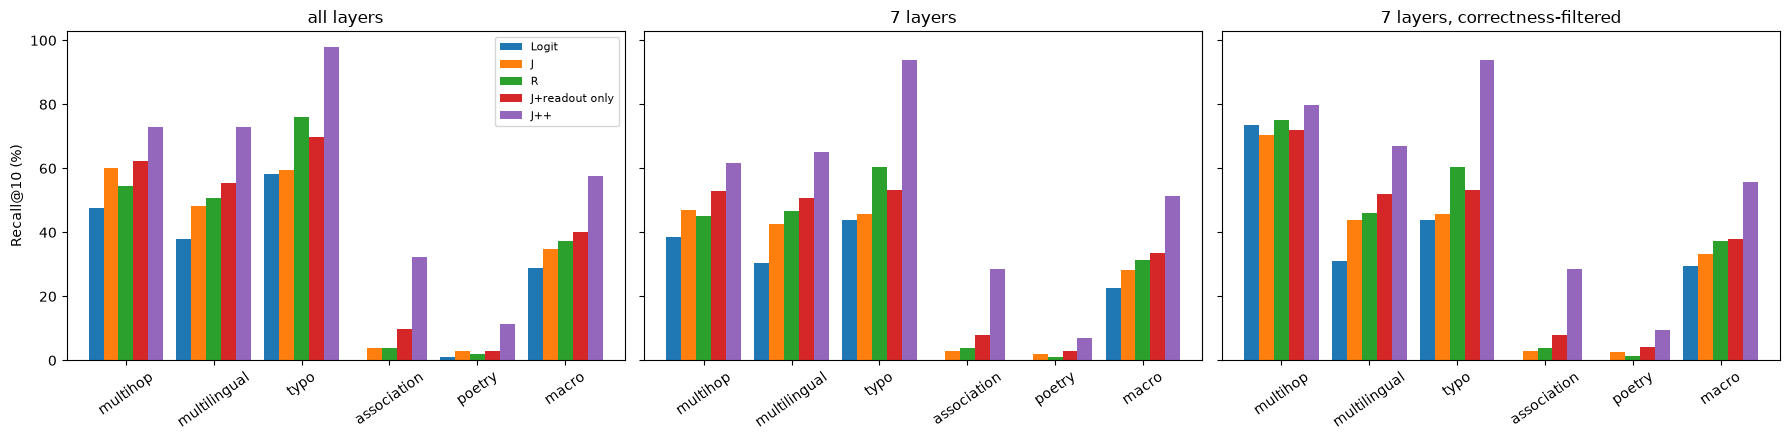

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18,4.5), sharey=True)
for ax,(k,t) in zip(axes, tables.items()):
    t.plot.bar(ax=ax, width=0.85, legend=False); ax.set_title(k); ax.set_ylabel("Recall@10 (%)"); ax.tick_params(axis="x", rotation=35)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Macro average and gain over J

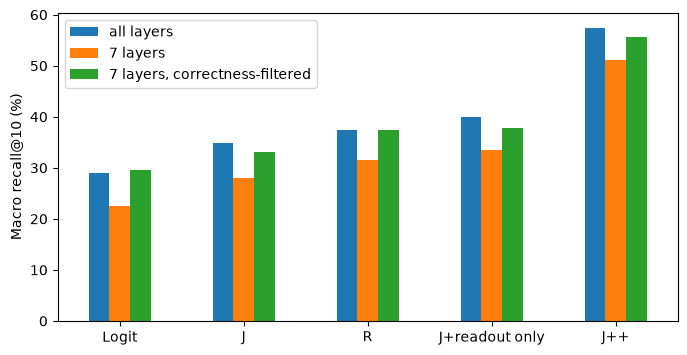

J++ minus J (points):


,all layers,7 layers,"7 layers, correctness-filtered"
multihop,12.9,14.7,9.4
multilingual,24.5,22.4,23.2
typo,38.5,47.9,47.9
association,28.4,25.5,25.5
poetry,8.2,5.1,6.8
macro,22.5,23.1,22.5


J+readout minus J (points, all layers):


multihop         2.2
multilingual     7.0
typo            10.4
association      5.9
poetry           0.0
macro            5.1
dtype: float64

In [3]:
m = pd.DataFrame({k: t.loc["macro"] for k,t in tables.items()})
m.plot.bar(figsize=(8,4)); plt.ylabel("Macro recall@10 (%)"); plt.xticks(rotation=0); plt.show()
gain = pd.DataFrame({k: t["J++"]-t["J"] for k,t in tables.items()}).round(1)
print("J++ minus J (points):"); display(gain)
print("J+readout minus J (points, all layers):"); display((tables["all layers"]["J+readout only"]-tables["all layers"]["J"]).round(1))

## Takeaways
- Ordering reproduces: Logit < J < R < J+readout < J++ (macro 29 → 57%, all layers).
- Readout filter alone gives ~+5 pts; most of J++'s gain is the lens itself.
- Largest J++ gains: typo, association, multilingual. Poetry is hard for all lenses.
- With correctness filter, multihop barely separates lenses (logit 73%, J++ 80%; only 32 items).
- Arithmetic intervention (one problem, supplied CoT) is inconclusive.

**Caveats:** 9B/4-bit, differing fitting budgets, J++ mixer training membership unknown, no significance tests, small denominators.

## Comparison with the papers

**J++ paper** (Ayonrinde & Lindsey 2026), numbers from the local PDF:
- Table 1: macro recall@10, Qwen3.5-9B column (same model as ours). *All lenses there are scored with Readout Filtering.*
- Table 3b: per-task recall@10 over the seven readout layers, **Qwen3.6-27B**, not 9B.

**J-lens paper** (arXiv 2607.15495): reports pass@k / pass@k-AUC mostly as figures on Claude models. I found no Qwen results table to compare numerically, so there is no J-lens-paper row below. Its metric is the same intermediate-concept recovery, but a different model and summary (AUC).

The paper's Table 1 uses seven layers, so compare against our *7 layers* protocol.

,paper 9B (all +readout filt.),ours 7 layers (J++ & 'J+readout' filtered),"ours 7 layers, J/R unfiltered","ours 7 layers, correctness-filt.",ours(filt.) - paper
Logit,29.7,22.58,22.58,29.64,-7.1
J,34.2,33.57,28.10,33.15,-0.6
R,37.5,31.47,31.47,37.37,-6.0
J++,55.0,51.21,51.21,55.69,-3.8


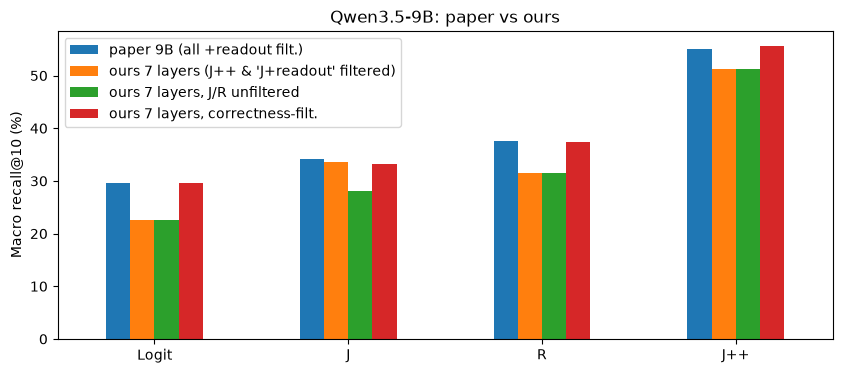

In [4]:
# J++ paper, Table 1 (macro recall@10, Qwen3.5-9B, all lenses with Readout Filtering)
paper_9b = pd.Series({"Logit":29.7,"J":34.2,"R":37.5,"J++":55.0})
ours_7 = tables["7 layers"].loc["macro"]
ours_7_corr = tables["7 layers, correctness-filtered"].loc["macro"]
cmp9 = pd.DataFrame({
    "paper 9B (all +readout filt.)": paper_9b,
    "ours 7 layers (J++ & 'J+readout' filtered)": pd.Series({"Logit":ours_7["Logit"],"J":ours_7["J+readout only"],"R":ours_7["R"],"J++":ours_7["J++"]}),
    "ours 7 layers, J/R unfiltered": pd.Series({"Logit":ours_7["Logit"],"J":ours_7["J"],"R":ours_7["R"],"J++":ours_7["J++"]}),
    "ours 7 layers, correctness-filt.": pd.Series({"Logit":ours_7_corr["Logit"],"J":ours_7_corr["J"],"R":ours_7_corr["R"],"J++":ours_7_corr["J++"]}),
})
cmp9["ours(filt.) - paper"] = (cmp9.iloc[:,1]-cmp9.iloc[:,0]).round(1)
display(cmp9)
cmp9.iloc[:,:4].plot.bar(figsize=(10,4)); plt.ylabel("Macro recall@10 (%)"); plt.xticks(rotation=0); plt.title("Qwen3.5-9B: paper vs ours"); plt.show()

paper 27B                   ours 9B                  
                 Logit     J     R   J++   Logit     J     R   J++
multihop          55.1  56.1  59.2  67.3    38.7  47.0  45.2  61.7
multilingual      30.7  47.4  47.4  74.6    30.4  42.7  46.7  65.0
typo              57.3  60.4  66.7  91.7    43.8  45.8  60.4  93.8
association        8.8  10.8  12.7  37.3     0.0   2.9   3.9  28.4
poetry             3.7   3.7   2.5   4.9     0.0   2.0   1.0   7.1
macro             31.1  35.7  37.7  55.2    22.6  28.1  31.5  51.2

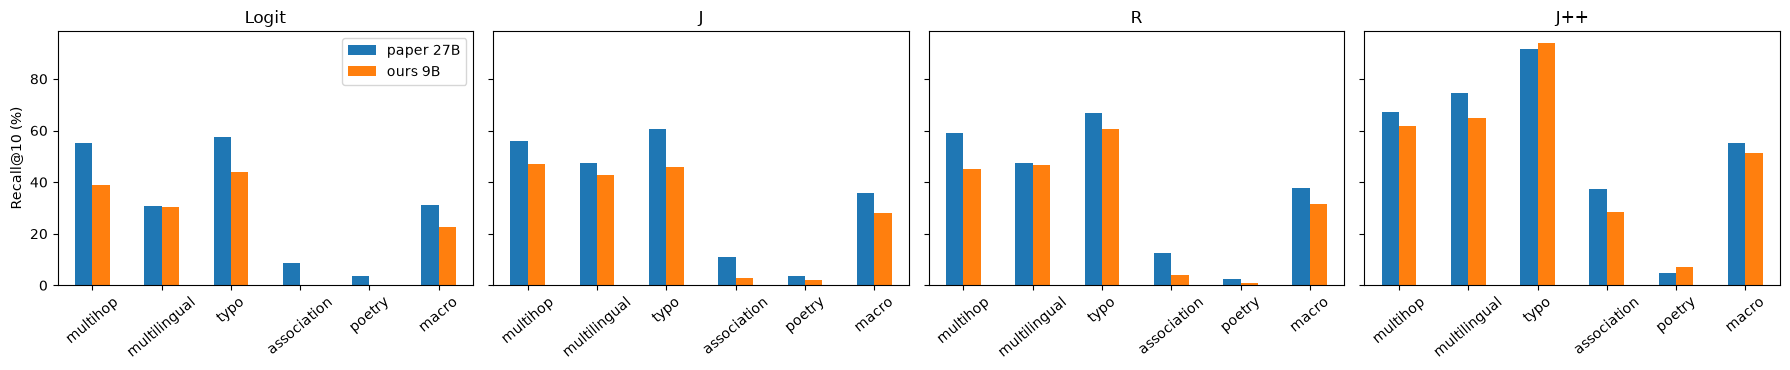

J++ uplift over J (relative):  paper 9B 61%, paper 27B 55%, ours 9B (7 layers) 82%


In [5]:
# J++ paper, Table 3b: per-task recall@10, 7 readout layers, Qwen3.6-27B (different model from ours)
paper_27b = pd.DataFrame({
 "Logit":[55.1,30.7,57.3,8.8,3.7,31.1], "J":[56.1,47.4,60.4,10.8,3.7,35.7],
 "R":[59.2,47.4,66.7,12.7,2.5,37.7], "J++":[67.3,74.6,91.7,37.3,4.9,55.2]}, index=tasks)
ours = tables["7 layers"][["Logit","J","R","J++"]]
side = pd.concat({"paper 27B":paper_27b, "ours 9B":ours}, axis=1).round(1)
display(side)
fig, axes = plt.subplots(1,4, figsize=(18,3.8), sharey=True)
for ax,l in zip(axes, ["Logit","J","R","J++"]):
    pd.DataFrame({"paper 27B":paper_27b[l],"ours 9B":ours[l]}).plot.bar(ax=ax, legend=(l=="Logit")); ax.set_title(l); ax.tick_params(axis="x", rotation=40)
axes[0].set_ylabel("Recall@10 (%)"); plt.tight_layout(); plt.show()
print("J++ uplift over J (relative):  paper 9B %.0f%%, paper 27B %.0f%%, ours 9B (7 layers) %.0f%%" % (
    100*(55.0/34.2-1), 100*(55.2/35.7-1), 100*(ours_7["J++"]/ours_7["J"]-1)))

### Reading the comparison
- **Qwen3.5-9B macro (7 layers):** J++ 51.2 vs paper 55.0, about 4 points lower. Ordering Logit < J < R < J++ matches.
- **Our J (unfiltered) 28.1** is below the paper's J (34.2), but the paper scores J *with* Readout Filtering; our J+readout-only ablation gives 33.6, close to 34.2.
- **Our R (31.5) is below the paper's 37.5.** The paper filters R with Readout Filtering too; we did not filter R.
- **Per task (27B paper vs our 9B):** same shape, J++ best everywhere and typo/association/multilingual benefit most. Poetry is near floor in both.
- **Not like-for-like:** 4-bit quantization, different model size in the per-task table, differing item correctness/scoreability filters, unknown held-out status of the released J++ mixer.
- **Uplift of J++ over J (relative):** paper +61% (9B) and +55% (27B); ours +82% (9B, 7 layers). Ours is larger because our J baseline is unfiltered; against J+readout-only it is +53%.